# CNN (Convolutional Neural Network)
##### checked 24.08.15 leebyunggook

In [2]:
import numpy as np
import tensorflow as tf
from IPython.display import Image
tf.random.set_seed(1)

In [3]:
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras import backend as K
from tensorflow.keras.losses import categorical_crossentropy
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from matplotlib import pyplot as plt

# Preprocessing

In [4]:
# collect MNIST data
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

In [5]:
# sample to show gray scale values
print(x_train[0][12])

[  0   0   0   0   0   0   0   0   0   0   0  11 190 253  70   0   0   0
   0   0   0   0   0   0   0   0   0   0]


In [6]:
# sample to show labels for first train data to 10th train data
print(y_train[0:9])

[5 0 4 1 9 2 1 3 1]


In [7]:
print("test data has " + str(x_test.shape[0]) + " samples")
print("every test data is " + str(x_test.shape[1])
      + " * " + str(x_test.shape[2]) + " image")

test data has 10000 samples
every test data is 28 * 28 image


In [8]:
# reshape data
x_train = np.reshape(x_train, (60000,28,28,1))
x_test = np.reshape(x_test, (10000,28,28,1))

print(x_train.shape)
print(x_test.shape)

(60000, 28, 28, 1)
(10000, 28, 28, 1)


In [9]:
# normalization
x_train = x_train.astype('float32')
x_test = x_test.astype('float32')

gray_scale = 255
x_train /= gray_scale
x_test /= gray_scale

In [10]:
# change label to one hot encoding
num_classes = 10
y_train_categorical = tf.keras.utils.to_categorical(y_train, num_classes)
y_test_categorical = tf.keras.utils.to_categorical(y_test, num_classes)

### We will implement below CNN

In [11]:
Image(url= "https://raw.githubusercontent.com/captainchargers/deeplearning/master/img/practice_cnn.png", width=800, height=400)

In [12]:
model = Sequential()
model.add(Conv2D(16, kernel_size=(5, 5), activation='relu', input_shape=(28,28,1),padding='same'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Conv2D(32, kernel_size=(5, 5), activation='relu',padding='same'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Flatten())
model.add(Dense(128, activation='relu'))
model.add(Dense(num_classes, activation='softmax'))

/opt/miniconda3/envs/tf/lib/python3.11/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [13]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 16)     │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 32)     │        12,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1568)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       200,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 215,370 (841.29 KB)

 Trainable params: 215,370 (841.29 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
model.compile(loss=categorical_crossentropy, optimizer=Adam(), metrics=['accuracy'])

In [15]:
#from google.colab import drive
#drive.mount('/content/drive')

In [16]:
#callbacks = [EarlyStopping(monitor='val_accuracy', patience=2, restore_best_weights=False),
#  ModelCheckpoint(filepath='./best_model.h5', monitor='val_accuracy', save_best_only=True)]

In [17]:
model.fit(x_train, y_train_categorical, batch_size=500, epochs=10, verbose=1, validation_split = 0.1) #, callbacks=callbacks)

Epoch 1/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 9s 76ms/step - accuracy: 0.8649 - loss: 0.4747 - val_accuracy: 0.9638 - val_loss: 0.1274
Epoch 2/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 8s 70ms/step - accuracy: 0.9680 - loss: 0.1078 - val_accuracy: 0.9802 - val_loss: 0.0718
Epoch 3/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 7s 65ms/step - accuracy: 0.9793 - loss: 0.0699 - val_accuracy: 0.9853 - val_loss: 0.0572
Epoch 4/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 7s 66ms/step - accuracy: 0.9836 - loss: 0.0544 - val_accuracy: 0.9870 - val_loss: 0.0505
Epoch 5/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 7s 67ms/step - accuracy: 0.9866 - loss: 0.0442 - val_accuracy: 0.9878 - val_loss: 0.0465
Epoch 6/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 7s 68ms/step - accuracy: 0.9890 - loss: 0.0369 - val_accuracy: 0.9883 - val_loss: 0.0440
Epoch 7/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 8s 70ms/step - accuracy: 0.9910 - loss: 0.0315 - val_accuracy: 0.9890 - val_loss: 0.0405
Epoch 8/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 8s 71ms/step - accuracy: 0.9921 - loss: 0.0275 - val_accu

In [18]:
score = model.evaluate(x_test, y_test_categorical, verbose=0)
print('Test loss:', score[0])
print('Test accuracy:', score[1])

Test loss: 0.033278413116931915
Test accuracy: 0.9883000254631042


In [19]:
i=200
image = x_test[i]*255
print(image.shape)
#print((image))

(28, 28, 1)


(28, 28)


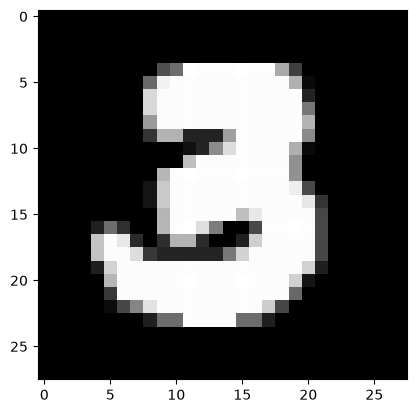

In [20]:
image = np.squeeze(image)
print(image.shape)
plt.imshow(image, cmap='gray')

In [21]:
print(y_test[i])
y_test_categorical[i]

3


array([0., 0., 0., 1., 0., 0., 0., 0., 0., 0.])

In [22]:
pred = model.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [23]:
np.set_printoptions(edgeitems=10, linewidth=130, formatter=dict(float=lambda x: "%4.2f" % x))
print(pred)

[[0.00 0.00 0.00 0.00 0.00 0.00 0.00 1.00 0.00 0.00]
 [0.00 0.00 1.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 1.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00]
 [1.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 0.00 0.00 0.00 1.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 1.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 0.00 0.00 0.00 1.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 1.00]
 [0.00 0.00 0.00 0.00 0.00 1.00 0.00 0.00 0.00 0.00]
 [0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 1.00]
 ...
 [0.00 0.00 0.00 0.00 0.00 0.00 0.00 1.00 0.00 0.00]
 [0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 1.00 0.00]
 [0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 1.00]
 [1.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 1.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 0.00 1.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 0.00 0.00 1.00 0.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 0.00 0.00 0.00 1.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 0.00 0.00 0.00 0.00 1.00 0.00 0.00

In [24]:
print(y_test_categorical)

[[0.00 0.00 0.00 0.00 0.00 0.00 0.00 1.00 0.00 0.00]
 [0.00 0.00 1.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 1.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00]
 [1.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 0.00 0.00 0.00 1.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 1.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 0.00 0.00 0.00 1.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 1.00]
 [0.00 0.00 0.00 0.00 0.00 1.00 0.00 0.00 0.00 0.00]
 [0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 1.00]
 ...
 [0.00 0.00 0.00 0.00 0.00 0.00 0.00 1.00 0.00 0.00]
 [0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 1.00 0.00]
 [0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 1.00]
 [1.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 1.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 0.00 1.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 0.00 0.00 1.00 0.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 0.00 0.00 0.00 1.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 0.00 0.00 0.00 0.00 1.00 0.00 0.00

In [25]:
s = 300
m = 20
images = x_test[s:s+m]*255
labels = y_test[s:s+m]

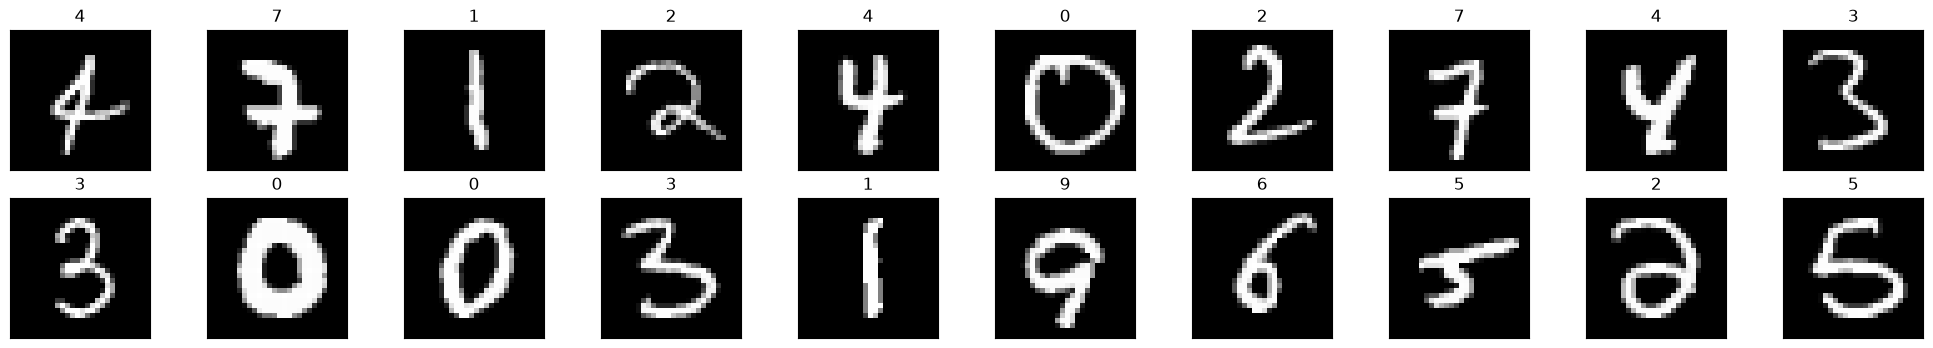

In [26]:
fig = plt.figure(figsize=(25, 4))
for idx in np.arange(m):
  ax = fig.add_subplot(2, (int)(m/2), idx+1, xticks=[], yticks=[])
  ax.imshow(np.squeeze(images[idx]), cmap='gray')
  ax.set_title(str(labels[idx].item()))

  ## 두개를 비교하는 방법에 대한것이 숙제

  

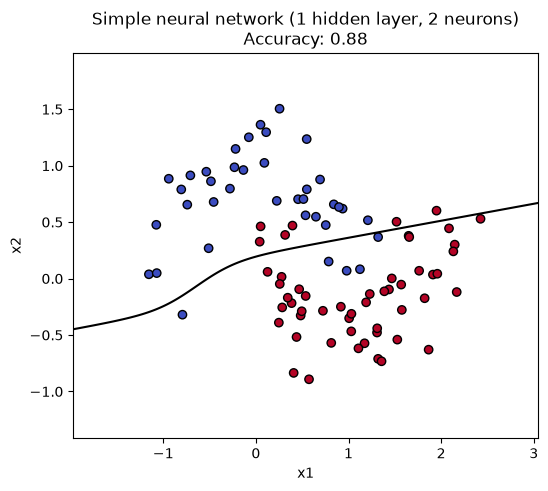

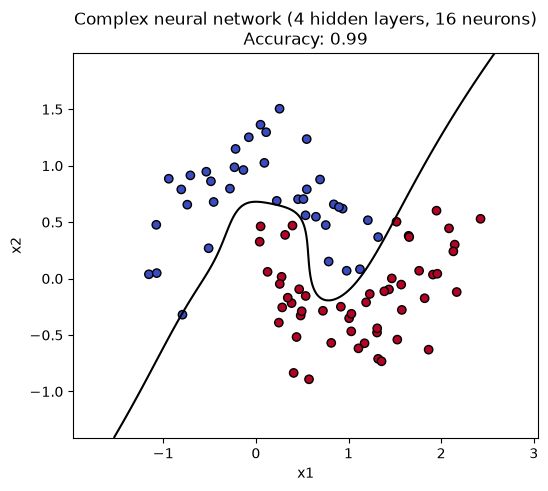

In [ ]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X_m, y_m = make_moons(n_samples=300, noise=0.2, random_state=42)
X_m_train, X_m_test, y_m_train, y_m_test = train_test_split(X_m, y_m, test_size=0.3, random_state=42)

def draw_boundary(net, title):
    net.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    net.fit(X_m_train, y_m_train, epochs=300, batch_size=10, verbose=0)

    y_m_pred = (net.predict(X_m_test, verbose=0) > 0.5).astype(int)
    acc = np.mean(y_m_pred.flatten() == y_m_test)

    x_min, x_max = X_m[:, 0].min() - 0.5, X_m[:, 0].max() + 0.5
    y_min, y_max = X_m[:, 1].min() - 0.5, X_m[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01), np.arange(y_min, y_max, 0.01))
    Z = net.predict(np.c_[xx.ravel(), yy.ravel()], verbose=0).reshape(xx.shape)

    plt.figure(figsize=(6, 5))
    plt.contour(xx, yy, Z, levels=[0.5], colors='black', linewidths=1.5)
    plt.scatter(X_m_test[:, 0], X_m_test[:, 1], c=y_m_test, cmap=plt.cm.coolwarm, edgecolors='k')
    plt.title(f"{title}\nAccuracy: {acc:.2f}")
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.show()

complex_net = Sequential([
    tf.keras.Input(shape=(2,)),
    Dense(units=16, activation='tanh'),
    Dense(units=16, activation='tanh'),
    Dense(units=16, activation='tanh'),
    Dense(units=16, activation='tanh'),
    Dense(units=1, activation='sigmoid')])
draw_boundary(complex_net, "Complex neural network (4 hidden layers, 16 neurons)")